# **Analisis Reliabilitas LLM-as-a-Judge pada Evaluasi Bahasa Indonesia**

_An Experimental Study of Prompt Sensitivity and Positional Bias in Indonesian Language Evaluation_

- **Author:** Rozhak  
- **Last Updated:** 7 November 2026  
- **Dataset:** IndoPref  
- **Evaluator:** `Qwen3-32B (Non-Thinking Mode, 8-bit INT8)`

**Description**

Pipeline evaluasi *end-to-end* untuk menguji konsistensi `Qwen3-32B` (`8-bit INT8`, *Non-Thinking Mode*) sebagai penilai pasangan jawaban berbahasa Indonesia pada dataset IndoPref. Eksperimen dijalankan pada 519 sampel unik menggunakan kombinasi 3 variasi prompt (`P1`, `P2`, `P3`) dan 2 urutan posisi jawaban (`AB`, `BA`) dengan total 3.114 inferensi.

**Purpose**

Mengukur tingkat kesesuaian pilihan model dengan preferensi manusia (*Accuracy* dan *Cohen's Kappa*), menguji konsistensi model terhadap perubahan urutan jawaban (*Position Consistency*, *Preference Flip Rate*, dan uji *McNemar*), serta mengevaluasi stabilitas pilihan model terhadap perbedaan variasi prompt (*Prompt Consistency* dan *Prompt Flip Rate*).

**Category:** Natural Language Processing / LLM Evaluation  
**Tags:** `llm`, `evaluation`, `reliability`, `indonesian-nlp`

# **1. Introduction**

### **1.1 Research Background**

Penggunaan *LLM-as-a-Judge* untuk menilai kualitas jawaban model bahasa sering menghadapi masalah konsistensi, terutama akibat bias urutan jawaban (*position bias*) dan sensitivitas terhadap perubahan variasi prompt (*prompt sensitivity*).

Meskipun masalah bias ini sudah banyak diteliti pada bahasa Inggris, pengujian sistematis pada bahasa Indonesia masih terbatas. Eksperimen ini mengevaluasi reliabilitas `Qwen3-32B` (*Non-Thinking Mode*, `8-bit INT8`) dalam menilai pasangan jawaban berbahasa Indonesia pada dataset IndoPref, dengan membandingkan pilihan model terhadap preferensi manusia (*human preference*).

### **1.2 Experimental Design**

Eksperimen dirancang menggunakan kombinasi 3 variasi prompt dan 2 urutan posisi jawaban pada 519 sampel data:

1. **Variasi Posisi (AB dan BA):** Setiap pasangan jawaban diuji pada urutan asli (`AB`) lalu posisinya ditukar (`BA`) untuk melihat apakah pilihan model tetap konsisten saat urutan jawaban dibalik.
2. **Variasi Prompt (P1, P2, P3):** Tiga variasi prompt dengan tujuan penilaian yang sama:
   - **P1 (Baseline):** Perbandingan pasangan jawaban secara menyeluruh untuk memilih jawaban yang lebih baik.
   - **P2 (Multi-criteria):** Penilaian berdasarkan tiga kriteria, yaitu Akurasi, Relevansi, dan Kejelasan.
   - **P3 (RCAF Constraint):** Penilaian dengan aturan tambahan untuk mengabaikan urutan posisi dan panjang jawaban.

Setiap sampel diuji pada 6 kombinasi kondisi (3 prompt $\times$ 2 posisi), sehingga menghasilkan total 3.114 proses inferensi.

### **1.3 Evaluation Metrics**

- **Accuracy:** Persentase kecocokan pilihan model dengan label preferensi manusia (*human preference*).
- **Cohen's Kappa:** Tingkat kesepakatan antara pilihan model dan preferensi manusia setelah memperhitungkan faktor kebetulan (*chance agreement*).
- **Position Consistency:** Persentase konsistensi pilihan model ketika urutan pasangan jawaban dibalik (antara urutan `AB` dan `BA`).
- **Preference Flip Rate:** Persentase berubahnya pilihan model akibat pertukaran urutan posisi jawaban.
- **McNemar Test:** Uji statistik non-parametrik ($\alpha = 0.05$) untuk menentukan apakah bias posisi yang terjadi signifikan secara statistik.
- **Prompt Consistency:** Persentase konsistensi pilihan model saat diuji menggunakan variasi prompt yang berbeda, baik antar dua prompt (*pairwise*) maupun ketiga prompt sekaligus (*3-way*).

### **1.4 Pipeline Workflow**

1. **Environment Setup:** Menyiapkan *library*, memeriksa perangkat GPU, menghubungkan Google Drive, dan login menggunakan token Hugging Face.
2. **Dataset Preparation:** Memuat data mentah IndoPref, memeriksa kelengkapan kolom, dan menyaring duplikasi hingga diperoleh 519 sampel unik.
3. **Model Loading & Quantization:** Memuat *tokenizer* dan model `Qwen3-32B` menggunakan kuantisasi `8-bit INT8` pada penyimpanan lokal *runtime*.
4. **Prompt Engineering:** Menyusun *template* instruksi `P1`, `P2`, dan `P3` dalam format *chat template* mode *non-thinking*.
5. **Model Inference:** Menjalankan inferensi berpasangan untuk 3.114 pengujian dengan penyimpanan hasil bertahap (*checkpoint*) ke Google Drive.
6. **Reliability Metric Evaluation:** Mengekstrak huruf pilihan model, mencocokkannya dengan label *ground truth*, serta menghitung metrik evaluasi dan uji statistik McNemar.
7. **Result Visualization:** Membuat grafik hasil evaluasi dalam format PNG dan SVG beresolusi 300 DPI.

## **2. Environment Setup**

Menyiapkan *library*, konfigurasi direktori kerja, pemeriksaan GPU, serta koneksi ke penyimpanan dan Hugging Face.

### **2.1 Dependency Installation**

Menginstal dan mengimpor seluruh *library* utama yang dibutuhkan di sepanjang *pipeline*, mulai dari pengolahan tabel dan pembacaan dataset Hugging Face, pemuatan model di atas PyTorch dengan kuantisasi 8-bit, hingga perhitungan statistik (*Cohen's Kappa* dan uji *McNemar*) serta pembuatan grafik. Setelah semua modul berhasil dimuat, kode mencetak pesan status bahwa lingkungan siap digunakan.

In [1]:
!pip install -q datasets pyarrow pandas matplotlib seaborn transformers accelerate bitsandbytes scikit-learn statsmodels

In [2]:
import datetime
import json
import os
import gc
import re
import time
import shutil
from typing import Tuple, List, Dict, Any, Optional

import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Patch

from datasets import load_dataset
from sklearn.model_selection import train_test_split

import torch
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

from sklearn.metrics import cohen_kappa_score
from statsmodels.stats.contingency_tables import mcnemar

print(
    f"[ENVIRONMENT] status=READY | "
    f"dependencies=torch,transformers,datasets,bitsandbytes,scikit-learn | "
    f"libraries=IMPORTED"
)

[ENVIRONMENT] status=READY | dependencies=torch,transformers,datasets,bitsandbytes,scikit-learn | libraries=IMPORTED


### **2.2 Hardware and Runtime Verification**

Mengatur lokasi penyimpanan, parameter dasar eksperimen, serta mengecek ketersediaan GPU beserta kapasitas VRAM-nya. Folder dataset dan hasil evaluasi diarahkan ke Google Drive agar tersimpan permanen, sedangkan *cache* bobot model Qwen3-32B ditempatkan di penyimpanan lokal Colab untuk menghindari lambatnya proses baca-tulis melalui Google Drive.

In [3]:
PROJECT_ROOT: str = '/content/drive/MyDrive/LLMReliability'
DATA_RAW_DIR: str = os.path.join(PROJECT_ROOT, 'data', 'raw')
DATA_PROCESSED_DIR: str = os.path.join(PROJECT_ROOT, 'data', 'processed')
MODELS_DIR: str = '/content/models'
RESULTS_DIR: str = os.path.join(PROJECT_ROOT, 'results')
MODEL_ID: str = 'Qwen/Qwen3-32B'

RANDOM_SEED: int = 42

os.environ['HF_HOME'] = MODELS_DIR
os.environ['HF_HUB_DISABLE_PROGRESS_BARS'] = '1'

try:
    from transformers.utils import logging as hf_logging
    hf_logging.disable_progress_bar()
except Exception:
    pass

if torch.cuda.is_available():
    device_name: str = torch.cuda.get_device_name(0)
    vram_gb: float = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    device_info: str = f"CUDA | gpu='{device_name}' | vram={vram_gb:.2f} GB"
else:
    device_info: str = "CPU | warning=GPU_NOT_DETECTED"

print(
    f"[ENVIRONMENT] device={device_info} | "
    f"seed={RANDOM_SEED} | "
    f"model_id='{MODEL_ID}' | "
    f"status=CONFIGURED"
)

[ENVIRONMENT] device=CUDA | gpu='NVIDIA A100-SXM4-80GB' | vram=79.25 GB | seed=42 | model_id='Qwen/Qwen3-32B' | status=CONFIGURED


### **2.3 Storage and Authentication**

Menghubungkan Google Drive ke *runtime* (dilengkapi *fallback* otomatis bila dijalankan di komputer lokal) dan login ke Hugging Face menggunakan token yang tersimpan di `secrets.json`. Di akhir sel, seluruh folder kerja untuk data mentah, data bersih, *cache* model, dan hasil evaluasi otomatis dibuat jika belum tersedia.

In [4]:
try:
    from google.colab import drive
    drive.mount('/content/drive')

    secrets_path: str = '/content/drive/MyDrive/secrets.json'
    if os.path.exists(secrets_path):
        with open(secrets_path, 'r', encoding='utf-8') as f:
            secrets = json.load(f)
        hf_token: str = secrets.get('HF_TOKEN', '')
        if hf_token:
            from huggingface_hub import login
            login(token=hf_token)
            print("[ENVIRONMENT] status=AUTHENTICATED | component='HuggingFace'")
        else:
            print("[ENVIRONMENT] status=WARNING | component='HF_TOKEN not found in secrets.json'")
    else:
        print(f"[ENVIRONMENT] status=WARNING | component='secrets.json not found at {secrets_path}'")
except ImportError:
    print("[ENVIRONMENT] status=LOCAL | component='Google Drive'")

for d in [DATA_RAW_DIR, DATA_PROCESSED_DIR, MODELS_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)

print("[ENVIRONMENT] status=READY | directories='all_initialized'")

Mounted at /content/drive
[ENVIRONMENT] status=AUTHENTICATED | component='HuggingFace'
[ENVIRONMENT] status=READY | directories='all_initialized'


## **3. Dataset Preparation**

Mengambil dataset IndoPref, memvalidasi kelengkapan datanya, menyaring duplikasi prompt, dan menyimpan data siap uji dalam format Parquet.

### **3.1 Dataset Ingestion**

Memuat dataset IndoPref menggunakan pengecekan *cache* bertingkat agar tidak mengunduh ulang data setiap kali *notebook* dijalankan. Kode terlebih dahulu memeriksa ketersediaan data siap uji (*Silver cache*) lalu cadangan data mentah utuh (*Bronze cache*, lebih dari 519 baris) di Google Drive, dan hanya mengunduh 4.099 baris *split test* dari Hugging Face Hub apabila kedua *cache* tersebut belum tersedia.

In [5]:
eval_path: str = os.path.join(DATA_PROCESSED_DIR, 'indopref_eval_stratified.parquet')
raw_path: str = os.path.join(DATA_RAW_DIR, 'indopref_raw.parquet')

EVAL_SAMPLE_SIZE: Optional[int] = None # 150
FORCE_REGENERATE_DATA: bool = False # True

df_raw: Optional[pd.DataFrame] = None
df_clean: Optional[pd.DataFrame] = None
df_eval: Optional[pd.DataFrame] = None

use_existing_silver: bool = False
if os.path.exists(eval_path) and not FORCE_REGENERATE_DATA:
    cached_silver = pd.read_parquet(eval_path)
    size_matched = (
        (EVAL_SAMPLE_SIZE is None and len(cached_silver) >= 500) or
        (EVAL_SAMPLE_SIZE is not None and len(cached_silver) == EVAL_SAMPLE_SIZE)
    )
    if size_matched:
        df_eval = cached_silver
        use_existing_silver = True
        print(f"[DATASET] status=CACHE_HIT | tier='processed_silver' | samples={len(df_eval)} | path='{eval_path}'")
    else:
        target_str = 'FULL (>=500)' if EVAL_SAMPLE_SIZE is None else str(EVAL_SAMPLE_SIZE)
        print(f"[DATASET] status=CACHE_INVALIDATED | reason='sample_size_changed' | cached={len(cached_silver)} | target={target_str}")

if not use_existing_silver:
    raw_cache_valid: bool = False
    if os.path.exists(raw_path):
        cached_raw = pd.read_parquet(raw_path)
        if len(cached_raw) > 519:
            df_raw = cached_raw
            raw_cache_valid = True
            print(f"[DATASET] status=CACHE_HIT | tier='raw_bronze' | records={len(df_raw)} | path='{raw_path}'")
        else:
            print(f"[DATASET] status=CACHE_INVALIDATED | tier='raw_bronze' | reason='contaminated_clean_rows' | cached={len(cached_raw)}")

    if not raw_cache_valid:
        print("[DATASET] status=CACHE_MISS | tier='remote_fetch' | id='davidanugraha/IndoPref'")
        dataset = load_dataset('davidanugraha/IndoPref', split='test')
        df_raw = dataset.to_pandas()
        df_raw.to_parquet(raw_path, index=False)
        print(f"[DATASET] status=PERSISTED_BRONZE | raw_records={len(df_raw)} | path='{raw_path}'")

[DATASET] status=CACHE_HIT | tier='processed_silver' | samples=519 | path='/content/drive/MyDrive/LLMReliability/data/processed/indopref_eval_stratified.parquet'


### **3.2 Schema Validator Definition**

Menyiapkan fungsi validasi untuk memastikan dataset memiliki enam kolom wajib (ID asli, domain, instruksi input, kedua jawaban, dan skor referensi manusia) sebelum masuk ke tahap berikutnya. Selain mengecek kelengkapan nama kolom, fungsi ini juga memastikan tidak ada nilai kosong (*null*) maupun teks yang hanya berisi spasi.

In [6]:
def validate_dataset_schema(df: pd.DataFrame) -> bool:
    required_cols: List[str] = ['original_id', 'domain', 'input', 'response_1', 'response_2', 'actual_score']
    missing = [c for c in required_cols if c not in df.columns]

    if missing:
        print(f"[VALIDATION] status=FAILED | error='missing_columns' | columns={missing}")
        return False
    if df[required_cols].isnull().sum().sum() > 0:
        print("[VALIDATION] status=FAILED | error='null_values'")
        return False
    for col in ['input', 'response_1', 'response_2']:
        if (df[col].astype(str).str.strip() == '').any():
            print(f"[VALIDATION] status=FAILED | error='empty_string' | column='{col}'")
            return False
        
    print("[VALIDATION] status=PASSED | schema='valid'")
    return True

### **3.3 Schema Integrity Verification**

Menjalankan fungsi validasi skema pada dataset yang aktif. Apabila ditemukan kolom yang hilang atau teks kosong, eksekusi *notebook* langsung dihentikan (*fail-fast*) agar kesalahan data tidak terbawa ke proses inferensi.

In [ ]:
target_df_to_check = df_eval if df_eval is not None else df_raw
if not validate_dataset_schema(target_df_to_check):
    raise ValueError("[VALIDATION] error='schema_verification_failed'")

print(
    f"[VALIDATION] dataset_shape={target_df_to_check.shape} | "
    f"required_columns={len(['original_id', 'domain', 'input', 'response_1', 'response_2', 'actual_score'])} | "
    f"null_counts=0 | "
    f"empty_strings=0 | "
    f"status=PASSED"
)

[VALIDATION] status=PASSED | schema='valid'
[VALIDATION] dataset_shape=(519, 10) | required_columns=6 | null_counts=0 | empty_strings=0 | status=PASSED


### **3.4 Sample Deduplication**

Menyaring baris duplikat pada data mentah berdasarkan ID prompt aslinya. Dataset mentah IndoPref memuat 4.099 baris perbandingan antar-model yang berasal dari 519 instruksi unik, sehingga penyaringan ini memastikan setiap instruksi hanya diuji satu kali dan tidak mendominasi hasil evaluasi (dilewati jika data langsung dimuat dari *Silver cache*).

In [ ]:
if df_eval is None and df_raw is not None:
    duplicates: int = int(df_raw.duplicated(subset=['original_id']).sum())
    if duplicates > 0:
        df_clean = df_raw.drop_duplicates(subset=['original_id']).copy()
        print(f"[VALIDATION] status=DEDUPLICATED | raw_records={len(df_raw)} | removed={duplicates} | clean_records={len(df_clean)}")
    else:
        df_clean = df_raw.copy()
        print(f"[VALIDATION] status=CLEAN | records={len(df_clean)}")
else:
    print("[VALIDATION] status=SKIPPED_DEDUP | reason='Loaded from pre-validated silver cache'")

[VALIDATION] status=SKIPPED_DEDUP | reason='Loaded from pre-validated silver cache'


### **3.5 Evaluation Cohort Sampling**

Menentukan himpunan sampel akhir yang akan masuk ke tahap pengujian model dan menyimpannya ke format Parquet. Secara bawaan seluruh 519 sampel unik digunakan penuh, namun jika batas jumlah sampel diaktifkan untuk pengujian cepat, data akan diambil secara berimbang mengikuti proporsi tiap kategori domain.

In [ ]:
if df_eval is None and df_clean is not None:
    if EVAL_SAMPLE_SIZE is not None and len(df_clean) > EVAL_SAMPLE_SIZE:
        df_eval, _ = train_test_split(
            df_clean,
            train_size=EVAL_SAMPLE_SIZE,
            stratify=df_clean['domain'],
            random_state=RANDOM_SEED
        )
        print(f"[DATASET] status=PERSISTED_SILVER | cohort_mode=subsample | samples={len(df_eval)} | stratify=domain | path='{eval_path}'")
    else:
        df_eval = df_clean.copy()
        print(f"[DATASET] status=PERSISTED_SILVER | cohort_mode=full_census | samples={len(df_eval)} | domain_balanced=True | path='{eval_path}'")
    df_eval.to_parquet(eval_path, index=False)
else:
    print(f"[DATASET] status=REUSED_SILVER | cohort_mode=full_census | samples={len(df_eval)} | path='{eval_path}'")

[DATASET] status=REUSED_SILVER | cohort_mode=full_census | samples=519 | path='/content/drive/MyDrive/LLMReliability/data/processed/indopref_eval_stratified.parquet'


### **3.6 Dataset Inspection and Sample Profiling**

Menampilkan ringkasan dataset evaluasi meliputi jumlah sampel, pemakaian memori, contoh beberapa baris awal, serta sebaran jumlah data di tiap kategori domain. Satu sampel pertama juga ditampilkan secara utuh untuk melihat bentuk riil instruksi, pasangan jawaban, dan label preferensi manusianya.

In [10]:
display_cols: List[str] = ['original_id', 'domain', 'input', 'response_1', 'response_2', 'actual_score']
print(f"[DATASET_INSPECTION] total_samples={len(df_eval)} | memory_usage={df_eval.memory_usage().sum() / 1024:.1f} KB")
display(df_eval[display_cols].head(3))

print("[DATASET_DISTRIBUTION] Komposisi Sampel per Domain:")
domain_dist = df_eval['domain'].value_counts().to_frame(name='Jumlah Sampel')
domain_dist['Persentase (%)'] = (domain_dist['Jumlah Sampel'] / len(df_eval) * 100).round(2)
display(domain_dist)

sample_row = df_eval.iloc[0]
raw_actual = str(sample_row.get('actual_score', 'N/A'))
print(f"[SAMPLE_METADATA] id={sample_row['original_id']} | domain='{sample_row['domain']}'")
print(f"[SAMPLE_INPUT] {sample_row['input']}")
print(f"[SAMPLE_RESPONSE_1] length={len(sample_row['response_1'])} chars | text:\n{sample_row['response_1']}")
print(f"[SAMPLE_RESPONSE_2] length={len(sample_row['response_2'])} chars | text:\n{sample_row['response_2']}")
print(f"[SAMPLE_GROUND_TRUTH] actual_score='{raw_actual}'")

[DATASET_INSPECTION] total_samples=519 | memory_usage=40.7 KB


,original_id,domain,input,response_1,response_2,actual_score
0,175,logic,Jika Anda menambah kecepatan kendaraan tiba-ti...,Jika Anda menambah kecepatan kendaraan tiba-ti...,Jika Anda menambah kecepatan kendaraan tiba-ti...,Assistant A
1,416,brainstorming,Jika Anda memiliki kesempatan untuk memulai ke...,Pertanyaan ini sangat menarik dan bisa memilik...,Keputusan untuk memulai kembali hidup di tempa...,Assistant B
2,140,logic,"Sebuah taman memiliki tiga jenis bunga: mawar,...",Melati berada di sebelah **mawar**. \n\nBeriku...,"Berdasarkan informasi yang diberikan, kita dap...",Assistant A


[DATASET_DISTRIBUTION] Komposisi Sampel per Domain:


,Jumlah Sampel,Persentase (%)
domain,,
brainstorming,70,13.49
translation,56,10.79
logic,53,10.21
summarization,50,9.63
analysis,50,9.63
open question,50,9.63
coding,50,9.63
math,49,9.44
safety,46,8.86


[SAMPLE_METADATA] id=175 | domain='logic'
[SAMPLE_INPUT] Jika Anda menambah kecepatan kendaraan tiba-tiba, apa efeknya pada rem?
[SAMPLE_RESPONSE_1] length=1324 chars | text:
Jika Anda menambah kecepatan kendaraan tiba-tiba (atau melakukan akselerasi cepat), efeknya pada rem akan signifikan dan dapat dijelaskan sebagai berikut:

1. **Tingkat Kekuatan Rem Meningkat**: Ketika Anda menekan pedal gas dengan kuat untuk mempercepat kendaraan, mesin menghasilkan torsi yang lebih besar, yang mendorong roda untuk berputar lebih cepat. Untuk menjaga kontrol kendaraan dan memperlambat atau berhenti, sistem rem harus bekerja lebih keras. Hal ini menyebabkan peningkatan kekuatan rem secara keseluruhan.

2. **Peningkatan Tekanan Rem**: Dalam situasi akselerasi cepat, sistem rem dirancang untuk menyesuaikan tekanan rem pada setiap roda secara individu. Rem di roda depan dan belakang mungkin mengalami tekanan yang lebih tinggi dibandingkan saat berkendara dengan kecepatan konstan. Hal ini memungkinkan

## **4. Model Loading and Quantization**

Memuat *tokenizer* dan bobot model Qwen3-32B ke memori GPU menggunakan kompresi kuantisasi 8-bit.

### **4.1 Tokenizer Initialization**

Menginisialisasi *tokenizer* bawaan Qwen3-32B dari direktori penyimpanan lokal dan menampilkan ukuran *vocabulary* sebagai pengecekan awal bahwa konfigurasi tokenisasi siap dipakai.

In [11]:
print(f"[MODEL] id='{MODEL_ID}' | status=LOADING_TOKENIZER")
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, cache_dir=MODELS_DIR)
print(f"[MODEL] status=TOKENIZER_READY | vocab_size={tokenizer.vocab_size}")

[MODEL] id='Qwen/Qwen3-32B' | status=LOADING_TOKENIZER


[MODEL] status=TOKENIZER_READY | vocab_size=151643


### **4.2 8-Bit Quantization Configuration**

Menyiapkan konfigurasi kuantisasi 8-bit melalui *bitsandbytes*. Pendekatan ini memangkas kebutuhan memori bobot model 32 miliar parameter hingga sekitar separuhnya sehingga dapat dimuat pada satu GPU tanpa mengorbankan stabilitas presisi aktivasi.

In [ ]:
bnb_config = BitsAndBytesConfig(
    load_in_8bit=True,
)

print(
    f"[QUANTIZATION] method='bitsandbytes_8bit' | "
    f"status=CONFIGURED"
)

[QUANTIZATION] method='bitsandbytes_8bit' | status=CONFIGURED


### **4.3 Weight Loading and Memory Profiling**

Memuat model ke GPU dengan penempatan memori otomatis dan konfigurasi kuantisasi 8-bit yang telah disiapkan. Tipe data komputasi disetel ke *float16* agar selaras dengan kernel matriks *bitsandbytes* dan mencegah konversi tipe data berulang saat inferensi, lalu ditutup dengan pencatatan pemakaian VRAM.

In [13]:
print(f"[MODEL] id='{MODEL_ID}' | status=LOADING_MODEL | cache_dir='{MODELS_DIR}'")
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    dtype=torch.float16,
    quantization_config=bnb_config,
    device_map='auto',
    cache_dir=MODELS_DIR
)

allocated_vram: float = torch.cuda.memory_allocated() / (1024**3)
reserved_vram: float = torch.cuda.memory_reserved() / (1024**3)

print(f"[MODEL] status=LOADED | device={model.device} | allocated_vram={allocated_vram:.2f} GB | reserved_vram={reserved_vram:.2f} GB")

[MODEL] id='Qwen/Qwen3-32B' | status=LOADING_MODEL | cache_dir='/content/models'


[MODEL] status=LOADED | device=cuda:0 | allocated_vram=31.98 GB | reserved_vram=32.60 GB


## **5. Prompt Engineering**

Menyusun tiga variasi *template* prompt penilaian, mengatur format percakapan model dalam mode *non-thinking*, serta memeriksa hasil tokenisasinya.

### **5.1 Prompt Strategy Definition**

Menyiapkan fungsi penyusun prompt untuk menguji apakah cara penulisan instruksi memengaruhi penilaian model melalui tiga variasi:

- **P1 (Baseline):** Meminta model membandingkan kedua jawaban secara menyeluruh dan langsung memilih mana yang lebih baik.
- **P2 (Multi-criteria):** Mengarahkan model untuk menilai berdasarkan tiga aspek utama, yaitu Akurasi, Relevansi, dan Kejelasan.
- **P3 (RCAF Constraint):** Menambahkan aturan tegas agar model mengabaikan urutan kemunculan jawaban maupun panjang pendeknya teks.

Ketiga variasi prompt ini sama-sama mengunci format jawaban agar model hanya mengeluarkan satu huruf (A atau B) tanpa penjelasan tambahan.

In [ ]:
def format_prompt(input_text: str, resp_A: str, resp_B: str, p_id: str) -> str:
    if p_id == 'P1':
        return (
            f"### TUGAS\nBandingkan dua respons AI di bawah ini untuk instruksi yang sama. Pilih mana yang secara keseluruhan lebih baik.\n\n"
            f"### INSTRUKSI\n{input_text}\n\n"
            f"### RESPONS A\n{resp_A}\n\n"
            f"### RESPONS B\n{resp_B}\n\n"
            f"### FORMAT JAWABAN\nKeluarkan HANYA satu huruf: A atau B. Dilarang menulis alasan atau teks lain."
        )
    elif p_id == 'P2':
        return (
            f"### TUGAS\nNilai dua respons AI berikut berdasarkan: Akurasi (kebenaran), Relevansi (menjawab instruksi), dan Kejelasan (tidak bertele-tele).\n\n"
            f"### INSTRUKSI\n{input_text}\n\n"
            f"### RESPONS A\n{resp_A}\n\n"
            f"### RESPONS B\n{resp_B}\n\n"
            f"### FORMAT JAWABAN\nBerdasarkan kriteria di atas, keluarkan HANYA satu huruf: A atau B. Dilarang memberikan penjelasan."
        )
    elif p_id == 'P3':
        return (
            f"### TUGAS\nTentukan respons terbaik untuk instruksi di bawah ini.\n\n"
            f"### INSTRUKSI\n{input_text}\n\n"
            f"### RESPONS A\n{resp_A}\n\n"
            f"### RESPONS B\n{resp_B}\n\n"
            f"### ATURAN KETAT\n- Abaikan urutan kemunculan respons (jangan bias posisi).\n- Abaikan panjang respons (jangan bias verbosity).\n- FORMAT JAWABAN WAJIB: Keluarkan hanya karakter A atau B."
        )
    return ""

print("[PROMPT_ENGINEERING] strategies=['P1_Baseline', 'P2_MultiCriteria', 'P3_RCAF'] | status=FUNCTIONS_DEFINED")

[PROMPT_ENGINEERING] strategies=['P1_Baseline', 'P2_MultiCriteria', 'P3_RCAF'] | status=FUNCTIONS_DEFINED


### **5.2 Chat Template Formatting**

Membungkus teks prompt penilaian ke dalam struktur percakapan resmi Qwen3 yang terdiri dari instruksi sistem (*system role*) sebagai penilai objektif dan pesan pengguna (*user role*) berisi pasangan jawaban. Fitur penalaran panjang internal pada Qwen3 dimatikan (*non-thinking mode*) supaya model langsung mengeluarkan huruf keputusan akhir dengan cepat dan hemat token.

In [ ]:
def apply_chat_template(tokenizer, text: str, enable_thinking: bool = False) -> str:
    messages = [
        {'role': 'system', 'content': 'Anda adalah evaluator AI yang objektif. Anda tidak memiliki bias posisi. Jawab HANYA dengan pilihan kandidat (A atau B).'},
        {'role': 'user', 'content': text}
    ]
    try:
        return tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True,
            enable_thinking=enable_thinking
        )
    except TypeError:
        return tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True
        )

print("[CHAT_TEMPLATE] model='Qwen3-32B' | mode='non_thinking' | add_generation_prompt=True | status=CONFIGURED")

[CHAT_TEMPLATE] model='Qwen3-32B' | mode='non_thinking' | add_generation_prompt=True | status=CONFIGURED


### **5.3 Concrete Prompt Inspection**

Mencoba fungsi pemformatan prompt pada satu sampel data untuk melihat bentuk teks akhir dan jumlah tokennya, baik pada urutan normal (AB), urutan terbalik (BA), maupun variasi aturan ketat (P3) sebelum menjalankan ribuan inferensi.

In [16]:
demo_sample = df_eval.iloc[0]
demo_input: str = demo_sample['input']
resp_1: str = demo_sample['response_1']
resp_2: str = demo_sample['response_2']

prompt_p1_ab: str = format_prompt(demo_input, resp_1, resp_2, p_id='P1')
chat_p1_ab: str = apply_chat_template(tokenizer, prompt_p1_ab)
tokens_ab: int = len(tokenizer.encode(chat_p1_ab))

prompt_p1_ba: str = format_prompt(demo_input, resp_2, resp_1, p_id='P1')
chat_p1_ba: str = apply_chat_template(tokenizer, prompt_p1_ba)
tokens_ba: int = len(tokenizer.encode(chat_p1_ba))

print(f"[PROMPT_INSPECTION] condition='AB' | strategy='P1' | tokens={tokens_ab}")
print(chat_p1_ab)
print(f"[PROMPT_INSPECTION] condition='BA' | strategy='P1' | tokens={tokens_ba}")
print(chat_p1_ba)

prompt_p3_ab: str = format_prompt(demo_input, resp_1, resp_2, p_id='P3')
chat_p3_ab: str = apply_chat_template(tokenizer, prompt_p3_ab)
tokens_p3: int = len(tokenizer.encode(chat_p3_ab))
print(f"[PROMPT_INSPECTION] condition='AB' | strategy='P3_RCAF' | tokens={tokens_p3} | status=VERIFIED")

[PROMPT_INSPECTION] condition='AB' | strategy='P1' | tokens=798
<|im_start|>system
Anda adalah evaluator AI yang objektif. Anda tidak memiliki bias posisi. Jawab HANYA dengan pilihan kandidat (A atau B).<|im_end|>
<|im_start|>user
### TUGAS
Bandingkan dua respons AI di bawah ini untuk instruksi yang sama. Pilih mana yang secara keseluruhan lebih baik.

### INSTRUKSI
Jika Anda menambah kecepatan kendaraan tiba-tiba, apa efeknya pada rem?

### RESPONS A
Jika Anda menambah kecepatan kendaraan tiba-tiba (atau melakukan akselerasi cepat), efeknya pada rem akan signifikan dan dapat dijelaskan sebagai berikut:

1. **Tingkat Kekuatan Rem Meningkat**: Ketika Anda menekan pedal gas dengan kuat untuk mempercepat kendaraan, mesin menghasilkan torsi yang lebih besar, yang mendorong roda untuk berputar lebih cepat. Untuk menjaga kontrol kendaraan dan memperlambat atau berhenti, sistem rem harus bekerja lebih keras. Hal ini menyebabkan peningkatan kekuatan rem secara keseluruhan.

2. **Peningkatan Te

## **6. Model Inference**

Menjalankan pengujian berpasangan untuk seluruh 3.114 kombinasi evaluasi (519 sampel x 3 variasi prompt x 2 urutan posisi) dengan penyimpanan bertahap ke Google Drive.

### **6.1 Inference Progress Tracking**

Menyiapkan fungsi pencatat progres untuk memantau jalannya inferensi di layar, meliputi persentase penyelesaian, durasi waktu berjalan, dan kecepatan pemrosesan (*tokens per second*) setiap kelipatan 15 pengujian.

In [ ]:
def log_progress(current: int, total: int, session_start: float, log_interval: int = 15, **kwargs):
    if (current % log_interval == 0) or (current >= total):
        elapsed: float = time.time() - session_start
        pct: float = (current / total) * 100.0 if total > 0 else 0.0
        metrics_str: str = ' | '.join([f"{k}={v}" for k, v in kwargs.items()])
        print(f"[EVALUATION] {pct:.1f}% ({current}/{total}) | elapsed={elapsed:.1f}s | {metrics_str}")

print("[EVALUATION] status=LOGGER_READY | log_interval=15")

[EVALUATION] status=LOGGER_READY | log_interval=15


### **6.2 Symmetric Paired Evaluation**

Menjalankan alur utama inferensi untuk menguji setiap sampel pada urutan normal (AB) maupun terbalik (BA) disertai penyesuaian label referensi manusia, sambil melewati kombinasi yang sudah tercatat di `main_outputs_final.jsonl` agar aman dilanjutkan jika koneksi *runtime* terputus. Model dijalankan secara deterministik tanpa pengacakan (*greedy decoding*), di mana setiap hasil langsung disimpan per baris diikuti pembersihan *cache* VRAM supaya memori GPU tetap stabil.

In [ ]:
out_file: str = os.path.join(RESULTS_DIR, 'main_outputs_final.jsonl')
prompts: List[str] = ['P1', 'P2', 'P3']
positions: List[str] = ['AB', 'BA']

def determine_human_winner(row_data: Any) -> str:
    if 'actual_score' in row_data:
        val: str = str(row_data['actual_score']).strip().upper()
        if 'ASSISTANT A' in val or val in ['A', '1', '1.0']:
            return 'A'
        if 'ASSISTANT B' in val or val in ['B', '2', '2.0']:
            return 'B'
        try:
            parsed_val = json.loads(str(row_data['actual_score']).replace("'", '"'))
            if isinstance(parsed_val, (list, tuple)) and len(parsed_val) >= 2:
                return 'A' if float(parsed_val[0]) >= float(parsed_val[1]) else 'B'
        except Exception:
            pass
    if 'model_1' in row_data and 'chosen_model' in row_data:
        if str(row_data['chosen_model']).strip() == str(row_data['model_1']).strip():
            return 'A'
        elif 'rejected_model' in row_data and str(row_data['rejected_model']).strip() == str(row_data['model_1']).strip():
            return 'B'
    if 'label' in row_data:
        l_val: str = str(row_data['label']).strip().upper()
        if 'ASSISTANT A' in l_val or l_val in ['1', '0', 'A']:
            return 'A'
        if 'ASSISTANT B' in l_val or l_val in ['2', 'B']:
            return 'B'
    return 'A'

In [19]:
processed_combinations: set = set()
if os.path.exists(out_file):
    with open(out_file, 'r', encoding='utf-8') as f:
        for line in f:
            if line.strip():
                record_item = json.loads(line)
                processed_combinations.add((record_item['sample_id'], record_item['prompt_id'], record_item['position']))

target_tasks: List[Dict[str, Any]] = []
for _, row in df_eval.iterrows():
    s_id: int = int(row['original_id'])
    for p_id in prompts:
        for pos in positions:
            target_tasks.append({
                'row': row,
                'sample_id': s_id,
                'prompt_id': p_id,
                'position': pos,
                'key': (s_id, p_id, pos)
            })

total_cohort_tasks: int = len(target_tasks)
pending_tasks: List[Dict[str, Any]] = [t for t in target_tasks if t['key'] not in processed_combinations]
already_completed: int = total_cohort_tasks - len(pending_tasks)

print(f"[RESUME] cohort_total={total_cohort_tasks} | already_completed={already_completed} | pending={len(pending_tasks)}")
print(f"[INFERENCE_CONFIG] sampling=False | max_new_tokens=10 | temperature=0.0 | format='JSONL' | sink='{out_file}'")

[RESUME] cohort_total=3114 | already_completed=3114 | pending=0
[INFERENCE_CONFIG] sampling=False | max_new_tokens=10 | temperature=0.0 | format='JSONL' | sink='/content/drive/MyDrive/LLMReliability/results/main_outputs_final.jsonl'


In [20]:
if not pending_tasks:
    print("[INFERENCE] status=ALREADY_COMPLETED | All cohort tasks exist in results.")
else:
    print(f"[INFERENCE] status=STARTED | remaining_evaluations={len(pending_tasks)}")
    current_step: int = already_completed
    inference_start_t: float = time.time()
    with torch.no_grad():
        for task in pending_tasks:
            current_step += 1
            row = task['row']
            sample_id = task['sample_id']
            p_id = task['prompt_id']
            pos = task['position']

            human_winner: str = determine_human_winner(row)
            if pos == 'AB':
                resp_A, resp_B = row['response_1'], row['response_2']
                current_human = human_winner
            else:
                resp_A, resp_B = row['response_2'], row['response_1']
                current_human = 'B' if human_winner == 'A' else 'A'

            start_t: float = time.time()
            raw_prompt: str = format_prompt(row['input'], resp_A, resp_B, p_id)
            formatted_prompt: str = apply_chat_template(tokenizer, raw_prompt)
            inputs = tokenizer(formatted_prompt, return_tensors='pt').to(model.device)

            outputs = model.generate(
                **inputs,
                max_new_tokens=10,
                do_sample=False,
                pad_token_id=tokenizer.eos_token_id
            )

            gen_tokens = outputs[0][inputs['input_ids'].shape[1]:]
            raw_out: str = tokenizer.decode(gen_tokens, skip_special_tokens=True)
            runtime_sec: float = round(time.time() - start_t, 2)
            tps: float = round(len(gen_tokens) / runtime_sec, 2) if runtime_sec > 0 else 0.0

            record: Dict[str, Any] = {
                'sample_id': sample_id,
                'domain': row['domain'],
                'prompt_id': p_id,
                'position': pos,
                'human_preference': current_human,
                'raw_output': raw_out,
                'runtime_sec': runtime_sec,
                'output_tokens': len(gen_tokens),
                'tps': tps
            }

            with open(out_file, 'a', encoding='utf-8') as f:
                f.write(json.dumps(record) + '\n')
                f.flush()

            processed_combinations.add((sample_id, p_id, pos))
            log_progress(current_step, total_cohort_tasks, inference_start_t, log_interval=15, ID=sample_id, Prompt=p_id, Pos=pos, TPS=tps)

            del inputs, outputs
            torch.cuda.empty_cache()
            gc.collect()

print(f"[INFERENCE] status=COMPLETED | sink='{out_file}'")

[INFERENCE] status=ALREADY_COMPLETED | All cohort tasks exist in results.
[INFERENCE] status=COMPLETED | sink='/content/drive/MyDrive/LLMReliability/results/main_outputs_final.jsonl'


## **7. Reliability Metric Evaluation**

Mengekstrak keputusan model dari hasil inferensi, menyelaraskan urutan jawaban, serta menghitung metrik akurasi, konsistensi posisi, uji statistik McNemar, dan stabilitas prompt.

### **7.1 Decision Extraction and Mapping**

Membaca seluruh hasil inferensi dari *file* JSONL dan mengekstrak huruf pilihan A atau B menggunakan *regex* (output di luar format ditandai tidak valid). Pilihan huruf tersebut kemudian dikembalikan ke identitas jawaban aslinya (jawaban 1 atau 2) karena pada urutan BA posisi kedua jawaban telah ditukar, lalu baris yang valid disaring dari kemungkinan duplikasi untuk diteruskan ke tahap perhitungan metrik.

In [ ]:
def parse_decision(raw_output: str) -> str:
    clean = str(raw_output).strip().upper()
    match = re.search(r'\b([AB])\b', clean)
    return match.group(1) if match else 'INVALID'

In [22]:
records: List[Dict[str, Any]] = []
with open(out_file, 'r', encoding='utf-8') as f:
    for line in f:
        if line.strip():
            records.append(json.loads(line))

if 'df_eval' in globals() and df_eval is not None:
    eval_gt_map = {int(r['original_id']): determine_human_winner(r) for _, r in df_eval.iterrows()}
    records_updated: bool = False
    for r in records:
        s_id = int(r['sample_id'])
        if s_id in eval_gt_map:
            true_winner = eval_gt_map[s_id]
            expected_human = true_winner if r['position'] == 'AB' else ('B' if true_winner == 'A' else 'A')
            if r.get('human_preference') != expected_human:
                r['human_preference'] = expected_human
                records_updated = True
    if records_updated:
        with open(out_file, 'w', encoding='utf-8') as f:
            for r in records:
                f.write(json.dumps(r) + '\n')
        print(f"[RECONCILIATION] status=SYNCHRONIZED | sink='{out_file}' | ground_truth_aligned=True")

for r in records:
    parsed: str = parse_decision(r['raw_output'])
    r['parsed_decision'] = parsed

    if parsed == 'INVALID':
        r['logical_decision'] = 'INVALID'
    elif r['position'] == 'AB':
        r['logical_decision'] = 1 if parsed == 'A' else 2
    else:
        r['logical_decision'] = 2 if parsed == 'A' else 1

    if r['position'] == 'AB':
        r['logical_human'] = 1 if r['human_preference'] == 'A' else 2
    else:
        r['logical_human'] = 2 if r['human_preference'] == 'A' else 1

df_all = pd.DataFrame(records).drop_duplicates(subset=['sample_id', 'prompt_id', 'position'], keep='last')
invalid_count: int = int((df_all['parsed_decision'] == 'INVALID').sum())
failure_rate: float = (invalid_count / len(df_all)) * 100

print(f"[PARSER] total_records={len(df_all)} | invalid={invalid_count} | failure_rate={failure_rate:.2f}%")

df_valid = df_all[df_all['parsed_decision'] != 'INVALID'].copy()

[PARSER] total_records=3114 | invalid=0 | failure_rate=0.00%


### **7.2 Positional Consistency Evaluation**

Memasangkan kembali hasil penilaian urutan AB dan BA pada tiap sampel untuk menghitung persentase konsistensi posisi (ketika pilihan jawaban tetap sama meski urutan dibalik) dan *flip rate* (ketika pilihan berubah akibat pertukaran posisi). Selain itu, dihitung pula seberapa sering model memilih opsi berlabel A secara keseluruhan untuk melihat indikasi awal kecenderungan ke urutan pertama.

In [23]:
df_pos = df_valid.pivot_table(
    index=['sample_id', 'prompt_id'],
    columns='position',
    values='logical_decision',
    aggfunc='first'
).dropna()

position_consistency: float = float((df_pos['AB'] == df_pos['BA']).mean() * 100)
position_flip: float = 100.0 - position_consistency
first_pos_rate: float = float((df_valid['parsed_decision'] == 'A').mean() * 100)

print(f"[METRICS] overall_consistency={position_consistency:.2f}%")
print(f"[METRICS] overall_flip_rate={position_flip:.2f}%")
print(f"[METRICS] first_position_selection_rate={first_pos_rate:.2f}%")

[METRICS] overall_consistency=68.46%
[METRICS] overall_flip_rate=31.54%
[METRICS] first_position_selection_rate=64.74%


### **7.3 McNemar Statistical Significance Test**

Menguji secara statistik apakah perubahan pilihan model antara urutan AB dan BA terjadi secara kebetulan atau menunjukkan bias posisi yang nyata menggunakan uji McNemar dengan koreksi kontinuitas (alpha = 0.05). Pengujian ini membandingkan jumlah kasus saat model terus memilih opsi urutan pertama (huruf A di kedua urutan) terhadap kasus saat model terus memilih opsi urutan kedua (huruf B di kedua urutan).

In [24]:
b: int = int(sum((df_pos['AB'] == 1) & (df_pos['BA'] == 2)))
c: int = int(sum((df_pos['AB'] == 2) & (df_pos['BA'] == 1)))

table = [[0, b], [c, 0]]
mcnemar_res = mcnemar(table, exact=False, correction=True)

is_significant: bool = bool(mcnemar_res.pvalue < 0.05)
conclusion_str: str = 'SIGNIFICANT_POSITION_BIAS_DETECTED' if is_significant else 'NO_SIGNIFICANT_BIAS'

print(
    f"[STATISTICS] test='McNemar' | "
    f"statistic={mcnemar_res.statistic:.4f} | "
    f"pvalue={mcnemar_res.pvalue:.5e} | "
    f"alpha=0.05 | "
    f"conclusion='{conclusion_str}'"
)

[STATISTICS] test='McNemar' | statistic=427.2179 | pvalue=6.55257e-95 | alpha=0.05 | conclusion='SIGNIFICANT_POSITION_BIAS_DETECTED'


### **7.4 Human Preference Alignment**

Mengukur tingkat kecocokan penilaian model terhadap preferensi manusia pada masing-masing variasi prompt (P1, P2, dan P3) menggunakan metrik akurasi dan skor *Cohen's Kappa* beserta estimasi rentang kepercayaan *bootstrap* 95% (500 iterasi). Seluruh rekapitulasi performa per prompt serta data hasil evaluasi yang valid kemudian diekspor ke format CSV dan Parquet.

In [25]:
def bootstrap_kappa(y_true: list, y_pred: list, n_iterations: int = 500, alpha: float = 0.05, seed: int = RANDOM_SEED) -> Tuple[float, float]:
    rng = np.random.default_rng(seed)
    stats = []
    yt, yp = np.array(y_true), np.array(y_pred)
    n = len(yt)

    for _ in range(n_iterations):
        idx = rng.integers(0, n, n)
        stats.append(cohen_kappa_score(yt[idx], yp[idx]))

    return float(np.percentile(stats, (alpha/2)*100)), float(np.percentile(stats, (1-alpha/2)*100))

In [26]:
metrics_summary = []
for p_id in prompts:
    sub = df_valid[df_valid['prompt_id'] == p_id]
    acc = (sub['logical_decision'] == sub['logical_human']).mean() * 100
    sub_pos = df_pos.xs(p_id, level='prompt_id') if p_id in df_pos.index.levels[1] else pd.DataFrame()
    consistency = (sub_pos['AB'] == sub_pos['BA']).mean() * 100 if not sub_pos.empty else 0.0

    kappa = cohen_kappa_score(list(sub['logical_decision']), list(sub['logical_human']))
    ci_low, ci_high = bootstrap_kappa(list(sub['logical_human']), list(sub['logical_decision']), n_iterations=500)

    metrics_summary.append({
        'Prompt': p_id,
        'Accuracy (%)': round(acc, 2),
        'Consistency (%)': round(consistency, 2),
        'Flip Rate (%)': round(100 - consistency, 2),
        'Cohen Kappa': round(kappa, 3),
        'Kappa 95% CI': f"[{ci_low:.3f}, {ci_high:.3f}]"
    })

df_metrics_table = pd.DataFrame(metrics_summary)
display(df_metrics_table)

sub_baseline = df_valid[(df_valid['prompt_id'] == 'P1') & (df_valid['position'] == 'AB')]
if not sub_baseline.empty:
    base_acc = (sub_baseline['logical_decision'] == sub_baseline['logical_human']).mean() * 100
    base_kappa = cohen_kappa_score(list(sub_baseline['logical_decision']), list(sub_baseline['logical_human']))

    print(f"[BASELINE] condition='P1_AB' | accuracy={base_acc:.2f}% | cohen_kappa={base_kappa:.3f}")

,Prompt,Accuracy (%),Consistency (%),Flip Rate (%),Cohen Kappa,Kappa 95% CI
0,P1,74.57,76.49,23.51,0.491,"[0.439, 0.543]"
1,P2,70.62,67.44,32.56,0.412,"[0.355, 0.470]"
2,P3,69.36,61.46,38.54,0.387,"[0.333, 0.443]"


[BASELINE] condition='P1_AB' | accuracy=76.49% | cohen_kappa=0.530


In [27]:
metrics_csv: str = os.path.join(RESULTS_DIR, 'evaluation_metrics_summary.csv')
metrics_parquet: str = os.path.join(RESULTS_DIR, 'evaluation_metrics_summary.parquet')
df_metrics_table.to_csv(metrics_csv, index=False)
df_metrics_table.to_parquet(metrics_parquet, index=False)

print(f"[ARTIFACT] table='Evaluation Metrics Summary' | formats=['CSV', 'Parquet'] | dir='{RESULTS_DIR}' | status=SAVED")

parsed_results_path: str = os.path.join(RESULTS_DIR, 'evaluation_results_detailed.parquet')
df_valid.to_parquet(parsed_results_path, index=False)

print(f"[ARTIFACT] table='Evaluation Results Detailed' | format='Parquet' | records={len(df_valid)} | path='{parsed_results_path}' | status=SAVED")

[ARTIFACT] table='Evaluation Metrics Summary' | formats=['CSV', 'Parquet'] | dir='/content/drive/MyDrive/LLMReliability/results' | status=SAVED
[ARTIFACT] table='Evaluation Results Detailed' | format='Parquet' | records=3114 | path='/content/drive/MyDrive/LLMReliability/results/evaluation_results_detailed.parquet' | status=SAVED


### **7.5 Prompt Stability Analysis**

Mengevaluasi kestabilan penilaian model ketika instruksi prompt diubah pada sampel yang sama (diuji pada urutan AB), baik untuk kesepakatan ketiga prompt sekaligus (P1, P2, dan P3) maupun perbandingan berpasangan antar dua prompt. Tabel stabilitas prompt serta rangkuman metrik utama keseluruhan *pipeline* selanjutnya disimpan ke *file* CSV di folder hasil.

In [28]:
prompt_consistency_3way: float = 0.0
prompt_flip_3way: float = 0.0

df_prompt_stab = df_valid[df_valid['position'] == 'AB'].pivot_table(
    index='sample_id',
    columns='prompt_id',
    values='logical_decision'
).dropna()

if not df_prompt_stab.empty:
    prompt_consistency_3way = float(((df_prompt_stab['P1'] == df_prompt_stab['P2']) & (df_prompt_stab['P2'] == df_prompt_stab['P3'])).mean() * 100)
    prompt_flip_3way = 100.0 - prompt_consistency_3way

    p1_p2_flip: float = float((df_prompt_stab['P1'] != df_prompt_stab['P2']).mean() * 100)
    p1_p3_flip: float = float((df_prompt_stab['P1'] != df_prompt_stab['P3']).mean() * 100)
    p2_p3_flip: float = float((df_prompt_stab['P2'] != df_prompt_stab['P3']).mean() * 100)

    prompt_stability_records = [
        {'Comparison': 'P1=P2=P3 (Simultaneous 3-Way)', 'Consistency (%)': round(prompt_consistency_3way, 2), 'Flip Rate (%)': round(prompt_flip_3way, 2)},
        {'Comparison': 'P1 vs P2 (Pairwise)', 'Consistency (%)': round(100.0 - p1_p2_flip, 2), 'Flip Rate (%)': round(p1_p2_flip, 2)},
        {'Comparison': 'P1 vs P3 (Pairwise)', 'Consistency (%)': round(100.0 - p1_p3_flip, 2), 'Flip Rate (%)': round(p1_p3_flip, 2)},
        {'Comparison': 'P2 vs P3 (Pairwise)', 'Consistency (%)': round(100.0 - p2_p3_flip, 2), 'Flip Rate (%)': round(p2_p3_flip, 2)}
    ]
    df_prompt_stability_summary = pd.DataFrame(prompt_stability_records)
    display(df_prompt_stability_summary)

    prompt_stab_csv: str = os.path.join(RESULTS_DIR, 'prompt_stability_summary.csv')
    df_prompt_stability_summary.to_csv(prompt_stab_csv, index=False)
    print(f"[ARTIFACT] table='Prompt Stability Summary' | format='CSV' | path='{prompt_stab_csv}' | status=SAVED")

exec_kpi_records = [
    {'Metric Category': 'Cohort Population', 'Specification': 'IndoPref Sensus Prompt Unik', 'Value': f"{len(df_eval)} samples ({len(df_valid):,} evaluations)"},
    {'Metric Category': 'Positional Reliability', 'Specification': 'Consistency (AB == BA)', 'Value': f"{position_consistency:.2f}%"},
    {'Metric Category': 'Positional Reliability', 'Specification': 'Preference Flip Rate', 'Value': f"{position_flip:.2f}%"},
    {'Metric Category': 'Positional Bias Test', 'Specification': 'McNemar Test (alpha=0.05)', 'Value': f"p = {mcnemar_res.pvalue:.2e} (Significant)" if is_significant else f"p = {mcnemar_res.pvalue:.2e} (Not Significant)"},
    {'Metric Category': 'Prompt Stability', 'Specification': 'Simultaneous 3-Way Consistency', 'Value': f"{prompt_consistency_3way:.2f}%"},
    {'Metric Category': 'Prompt Stability', 'Specification': 'Simultaneous 3-Way Flip Rate', 'Value': f"{prompt_flip_3way:.2f}%"}
]
if 'base_acc' in locals() or 'base_acc' in globals():
    exec_kpi_records.append({
        'Metric Category': 'Baseline Performance',
        'Specification': 'P1_AB Condition',
        'Value': f"Accuracy = {base_acc:.2f}% | Kappa = {base_kappa:.3f}"
    })

df_executive_summary = pd.DataFrame(exec_kpi_records)
display(df_executive_summary)

exec_summary_csv: str = os.path.join(RESULTS_DIR, 'executive_summary_kpi.csv')
df_executive_summary.to_csv(exec_summary_csv, index=False)
print(f"[ARTIFACT] table='Executive Summary KPI' | format='CSV' | path='{exec_summary_csv}' | status=SAVED")
print(f"[PIPELINE] status=COMPLETED | cohort={len(df_eval)} | instances={len(df_valid)} | sink='{RESULTS_DIR}'")

,Comparison,Consistency (%),Flip Rate (%)
0,P1=P2=P3 (Simultaneous 3-Way),83.04,16.96
1,P1 vs P2 (Pairwise),89.02,10.98
2,P1 vs P3 (Pairwise),86.71,13.29
3,P2 vs P3 (Pairwise),90.37,9.63


[ARTIFACT] table='Prompt Stability Summary' | format='CSV' | path='/content/drive/MyDrive/LLMReliability/results/prompt_stability_summary.csv' | status=SAVED


,Metric Category,Specification,Value
0,Cohort Population,IndoPref Sensus Prompt Unik,"519 samples (3,114 evaluations)"
1,Positional Reliability,Consistency (AB == BA),68.46%
2,Positional Reliability,Preference Flip Rate,31.54%
3,Positional Bias Test,McNemar Test (alpha=0.05),p = 6.55e-95 (Significant)
4,Prompt Stability,Simultaneous 3-Way Consistency,83.04%
5,Prompt Stability,Simultaneous 3-Way Flip Rate,16.96%
6,Baseline Performance,P1_AB Condition,Accuracy = 76.49% | Kappa = 0.530


[ARTIFACT] table='Executive Summary KPI' | format='CSV' | path='/content/drive/MyDrive/LLMReliability/results/executive_summary_kpi.csv' | status=SAVED
[PIPELINE] status=COMPLETED | cohort=519 | instances=3114 | sink='/content/drive/MyDrive/LLMReliability/results'


## **8. Result Visualization**

Membuat lima grafik beresolusi tinggi (300 DPI) dalam format PNG dan SVG untuk merangkum temuan akurasi, bias posisi, dan stabilitas prompt secara visual.

### **8.1 Visualization Setup**

Menyeragamkan tampilan visual seluruh grafik menggunakan tema *whitegrid* beresolusi 300 DPI serta menyiapkan fungsi bantu untuk pengaturan judul sumbu, pelabelan angka di ujung batang grafik, dan penyimpanan otomatis ke format PNG maupun vektor SVG.

In [29]:
sns.set_theme(style='whitegrid', font_scale=1.15)
plt.rcParams.update({
    'font.sans-serif': 'DejaVu Sans', 'font.family': 'sans-serif',
    'axes.titlesize': 12, 'axes.labelsize': 11,
    'xtick.labelsize': 10.5, 'ytick.labelsize': 10.5,
    'legend.fontsize': 9.5, 'figure.dpi': 300, 'savefig.dpi': 300
})

In [30]:
def annotate_bars(ax: plt.Axes, bars=None, yerr=None, fmt: str = "{:.2f}%", horizontal: bool = False) -> None:
    for i, b in enumerate(bars if bars is not None else ax.patches):
        val = b.get_width() if horizontal else b.get_height()
        span = b.get_height() if horizontal else b.get_width()
        if not np.isnan(val) and val > 0 and span > 0:
            err = yerr[i] if yerr is not None and i < len(yerr) else 0.0
            xy = (val + err, b.get_y() + span / 2) if horizontal else (b.get_x() + span / 2, val + err)
            ax.annotate(fmt.format(val), xy, xytext=(4, 0) if horizontal else (0, 4),
                        textcoords='offset points', ha='left' if horizontal else 'center',
                        va='center' if horizontal else 'bottom', fontsize=9.5 if horizontal else 10,
                        fontweight='bold', zorder=5,
                        bbox=dict(boxstyle='square,pad=0.15', fc='white', ec='none', alpha=0.9))

In [31]:
def plot_bars(ax: plt.Axes, x, y, palette: str, title: str, xlabel: str, ylabel: str,
              ylim: Tuple[float, float] = (0, 100), yerr=None, fmt: str = "{:.2f}%") -> None:
    bars = ax.bar(x, y, width=0.55, yerr=yerr, capsize=5 if yerr is not None else 0,
                  color=sns.color_palette(palette, len(x)), edgecolor='black', alpha=0.85)
    ax.set(xlabel=xlabel, ylabel=ylabel, ylim=ylim)
    ax.set_title(title, fontweight='bold', pad=10)
    err_top = yerr[1] if isinstance(yerr, list) and len(yerr) == 2 and isinstance(yerr[1], list) else yerr
    annotate_bars(ax, bars=bars, yerr=err_top, fmt=fmt)

In [32]:
def export_panels(fig: plt.Figure, axes, names: List[str], results_dir: str = RESULTS_DIR, dpi: int = 300) -> None:
    fig.tight_layout()
    ax_list = list(np.atleast_1d(axes))
    for target_ax, base_name in zip(ax_list, names):
        orig_title = target_ax.get_title()
        target_ax.set_title(re.sub(r'^[A-Z]\.\s+', '', orig_title), fontweight='bold', pad=10)
        for ax in ax_list:
            ax.set_visible(ax is target_ax)
        full_base = os.path.join(results_dir, base_name)
        fig.savefig(f"{full_base}.png", dpi=dpi, bbox_inches='tight')
        fig.savefig(f"{full_base}.svg", format='svg', bbox_inches='tight')
        target_ax.set_title(orig_title, fontweight='bold', pad=10)
        print(f"[VISUALIZATION] figure='{base_name}' | formats=['PNG', 'SVG'] | dir='{results_dir}' | status=SAVED")
    for ax in ax_list:
        ax.set_visible(True)
    plt.show()

print("[ENVIRONMENT] visualization_framework='Matplotlib/Seaborn' | theme='whitegrid' | base_dpi=300 | status=CONFIGURED")

[ENVIRONMENT] visualization_framework='Matplotlib/Seaborn' | theme='whitegrid' | base_dpi=300 | status=CONFIGURED


### **8.2 Figure 1: Accuracy and Position Distribution**

Membuat grafik dua panel yang menyandingkan persentase akurasi tiap variasi prompt (lengkap dengan *error bar* 95% terhadap garis acak 50%) pada Panel A dengan distribusi pemilihan huruf A dan B di urutan AB maupun BA pada Panel B untuk melihat gejala berat sebelah ke salah satu posisi.

[VISUALIZATION] figure='plot_model_accuracy' | formats=['PNG', 'SVG'] | dir='/content/drive/MyDrive/LLMReliability/results' | status=SAVED
[VISUALIZATION] figure='plot_slot_selection_distribution' | formats=['PNG', 'SVG'] | dir='/content/drive/MyDrive/LLMReliability/results' | status=SAVED


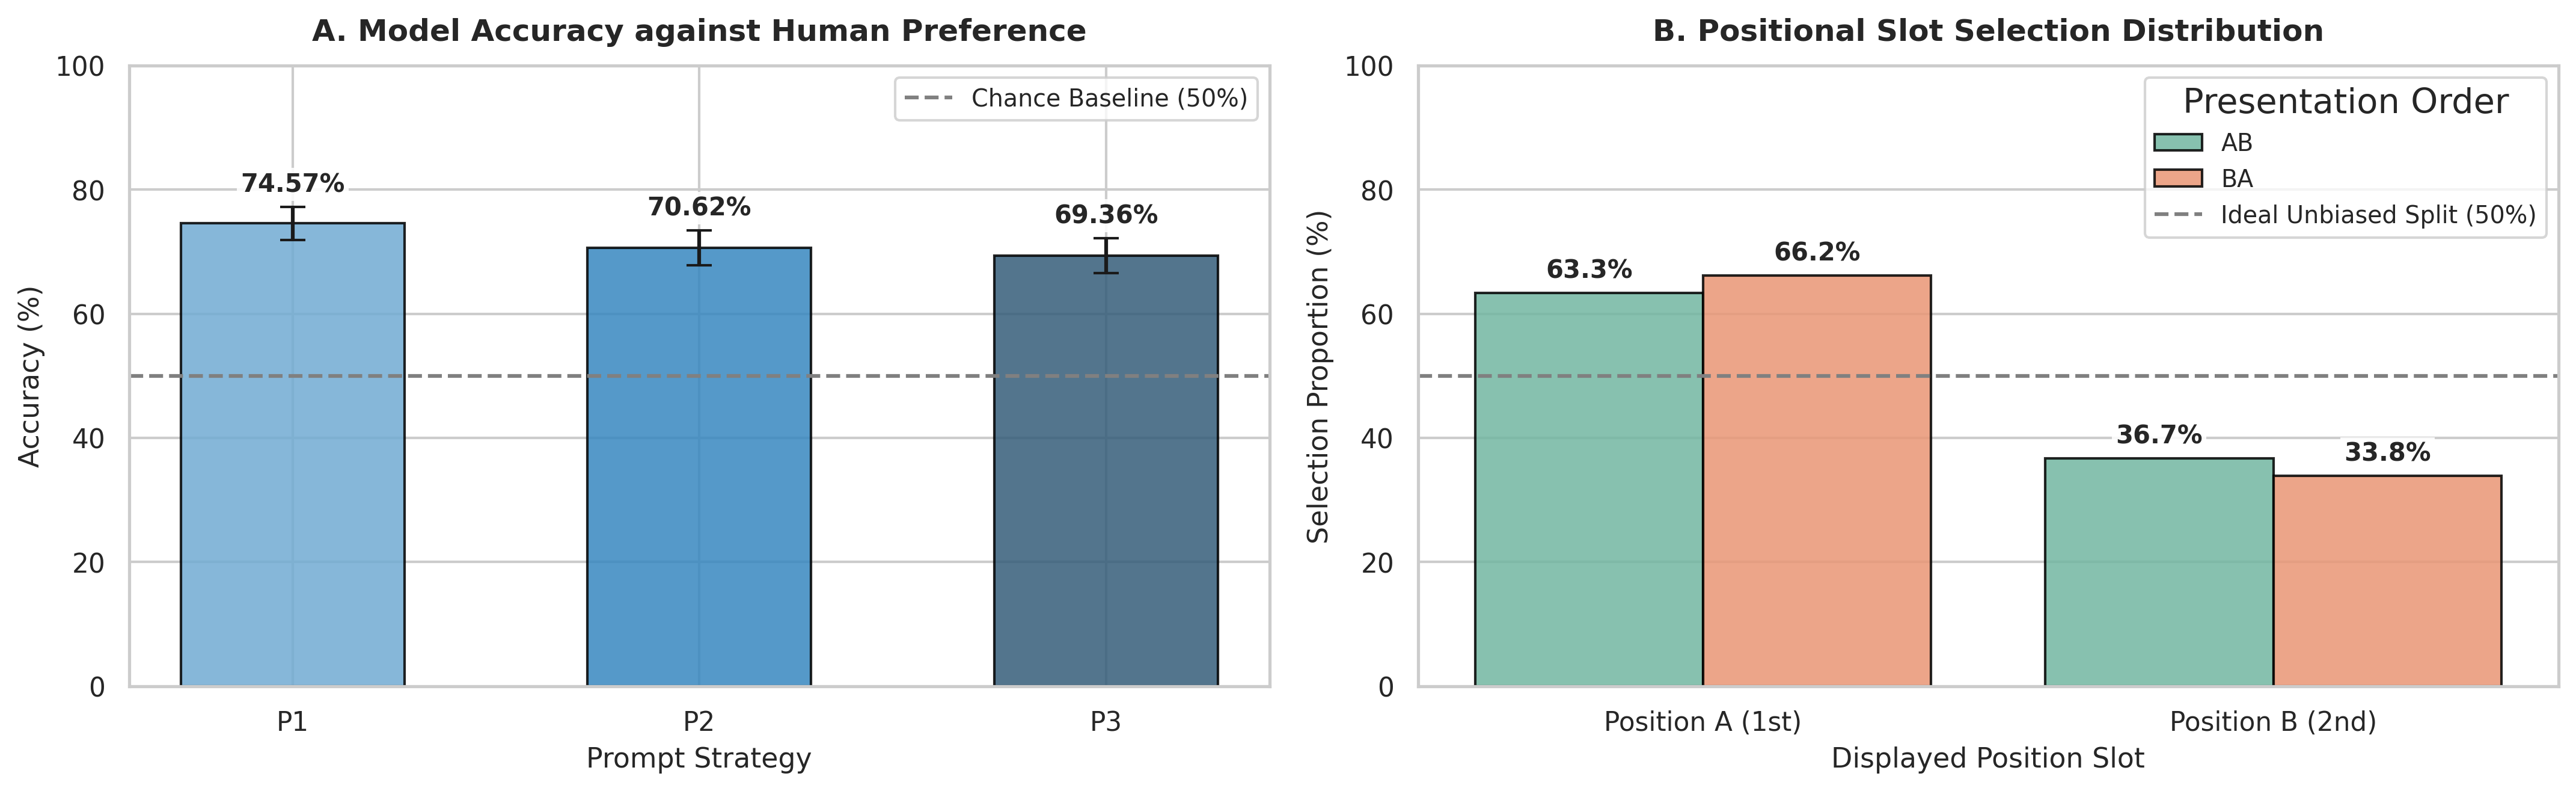

In [33]:
fig1, axes1 = plt.subplots(1, 2, figsize=(14.5, 4.6))

acc_s = (df_valid.assign(ok=(df_valid['logical_decision'] == df_valid['logical_human']) * 100)
         .groupby('prompt_id')['ok'].agg(['mean', 'count']).reindex(prompts).fillna(0))
acc_err = (1.96 * np.sqrt(acc_s['mean'] * (100 - acc_s['mean']) / acc_s['count'].replace(0, np.nan)).fillna(0)).tolist()

plot_bars(axes1[0], prompts, acc_s['mean'].tolist(), 'Blues_d',
          'A. Model Accuracy against Human Preference', 'Prompt Strategy', 'Accuracy (%)', yerr=acc_err)
axes1[0].axhline(50.0, color='gray', ls='--', lw=1.5, zorder=1, label='Chance Baseline (50%)')
axes1[0].legend(loc='upper right')

df_pos_dist = (df_valid.groupby(['position', 'parsed_decision']).size().unstack(fill_value=0)
               .reindex(columns=['A', 'B'], fill_value=0))
df_pos_dist = (df_pos_dist.div(df_pos_dist.sum(axis=1), axis=0) * 100).reset_index().melt(id_vars='position', var_name='Slot', value_name='Pct')
df_pos_dist['Slot'] = df_pos_dist['Slot'].map({'A': 'Position A (1st)', 'B': 'Position B (2nd)'})

sns.barplot(data=df_pos_dist, x='Slot', y='Pct', hue='position', ax=axes1[1], palette='Set2', edgecolor='black', alpha=0.85)
axes1[1].axhline(50.0, color='gray', ls='--', lw=1.5, zorder=1, label='Ideal Unbiased Split (50%)')
axes1[1].set(xlabel='Displayed Position Slot', ylabel='Selection Proportion (%)', ylim=(0, 100))
axes1[1].set_title('B. Positional Slot Selection Distribution', fontweight='bold', pad=10)
axes1[1].legend(title='Presentation Order', loc='upper right')
annotate_bars(axes1[1], fmt="{:.1f}%")

export_panels(fig1, axes1, ['plot_model_accuracy', 'plot_slot_selection_distribution'])

### **8.3 Figure 2: Consistency and Cohen Kappa Profile**

Menampilkan perbandingan keandalan antar variasi prompt dalam tiga panel berdampingan, mencakup persentase konsistensi posisi (Panel A), tingkat perubahan pilihan atau *flip rate* (Panel B), serta skor *Cohen's Kappa* terhadap preferensi manusia beserta batas kategori *Moderate* 0.40 dan *Substantial* 0.60 (Panel C).

[VISUALIZATION] figure='plot_positional_consistency' | formats=['PNG', 'SVG'] | dir='/content/drive/MyDrive/LLMReliability/results' | status=SAVED
[VISUALIZATION] figure='plot_positional_flip_rate' | formats=['PNG', 'SVG'] | dir='/content/drive/MyDrive/LLMReliability/results' | status=SAVED
[VISUALIZATION] figure='plot_cohen_kappa' | formats=['PNG', 'SVG'] | dir='/content/drive/MyDrive/LLMReliability/results' | status=SAVED


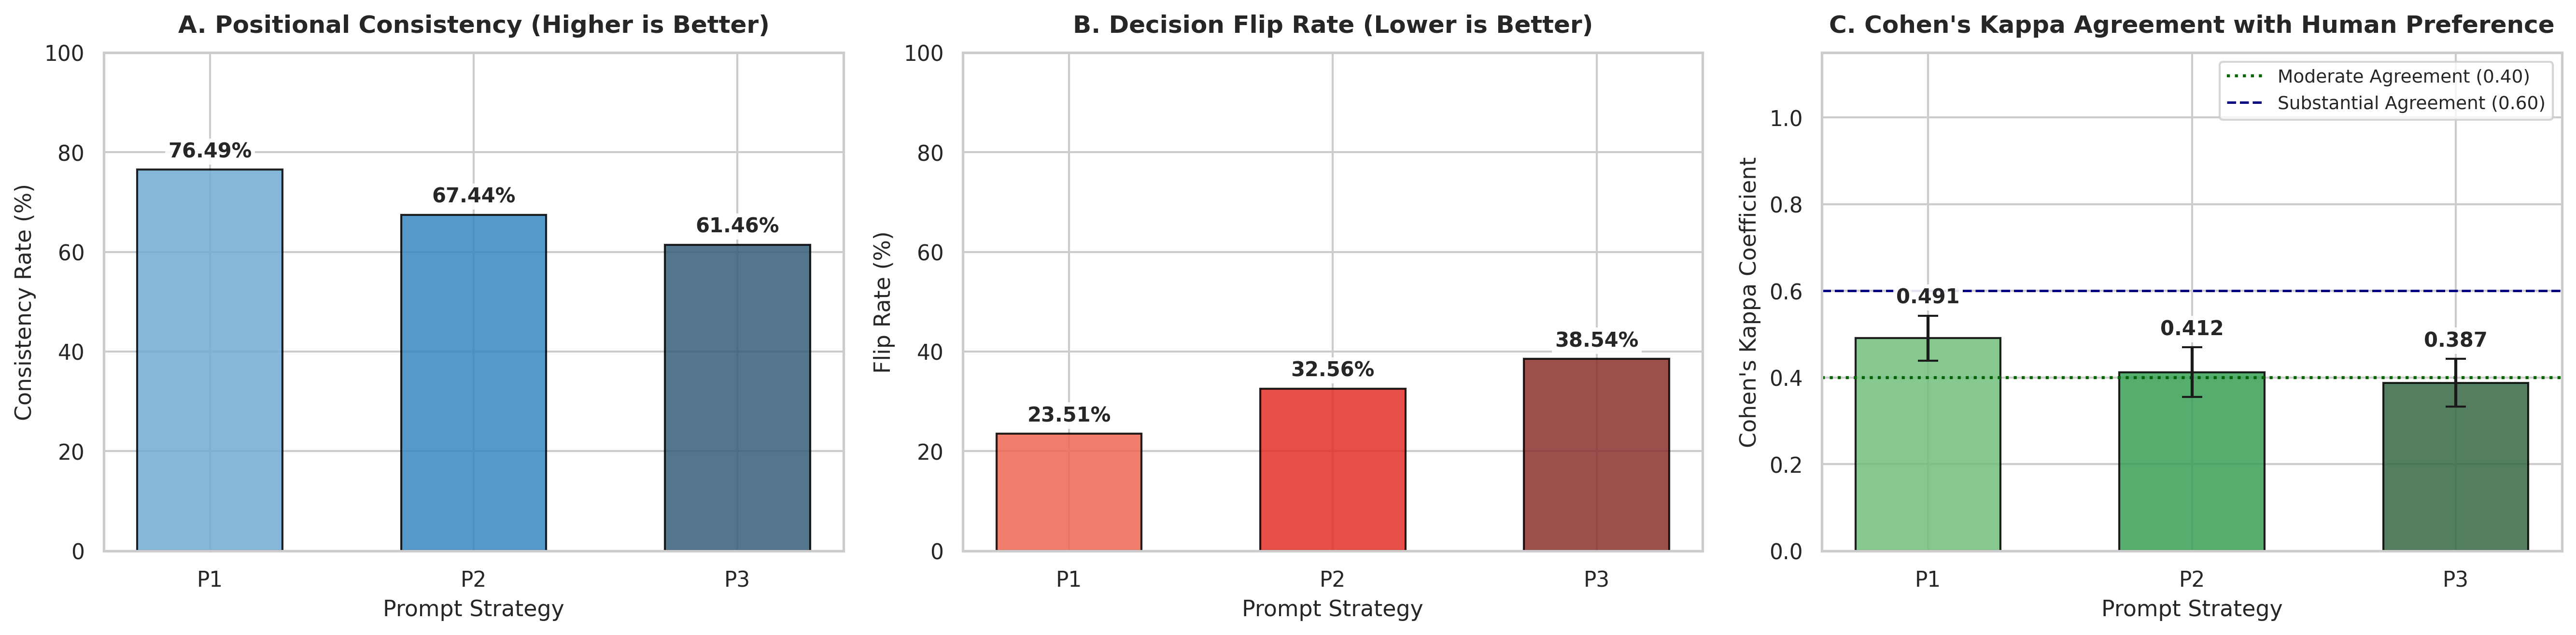

In [34]:
fig2, axes2 = plt.subplots(1, 3, figsize=(18.0, 4.6))

ci = df_metrics_table['Kappa 95% CI'].str.strip('[]').str.split(',', expand=True).astype(float)
k_vals = df_metrics_table['Cohen Kappa'].astype(float)
k_err = [(k_vals - ci[0]).clip(lower=0).tolist(), (ci[1] - k_vals).clip(lower=0).tolist()]

plot_bars(axes2[0], df_metrics_table['Prompt'], df_metrics_table['Consistency (%)'], 'Blues_d',
          'A. Positional Consistency (Higher is Better)', 'Prompt Strategy', 'Consistency Rate (%)')
plot_bars(axes2[1], df_metrics_table['Prompt'], df_metrics_table['Flip Rate (%)'], 'Reds_d',
          'B. Decision Flip Rate (Lower is Better)', 'Prompt Strategy', 'Flip Rate (%)')
plot_bars(axes2[2], df_metrics_table['Prompt'], k_vals.tolist(), 'Greens_d',
          "C. Cohen's Kappa Agreement with Human Preference", 'Prompt Strategy', "Cohen's Kappa Coefficient",
          ylim=(0.0, 1.15), yerr=k_err, fmt="{:.3f}")
axes2[2].axhline(0.40, color='darkgreen', ls=':', lw=1.5, zorder=1, label='Moderate Agreement (0.40)')
axes2[2].axhline(0.60, color='navy', ls='--', lw=1.2, zorder=1, label='Substantial Agreement (0.60)')
axes2[2].legend(loc='upper right', fontsize=9)

export_panels(fig2, axes2, ['plot_positional_consistency', 'plot_positional_flip_rate', 'plot_cohen_kappa'])

### **8.4 Figure 3: Semantic Parsing and Domain Accuracy**

Menyusun grafik *donut* untuk melihat rasio keberhasilan model mengeluarkan format huruf A atau B yang valid dibanding yang gagal diekstrak (Panel A), berdampingan dengan grafik batang horizontal yang mengurutkan akurasi model di tiap domain topik sekaligus menyimpannya ke *file* CSV (Panel B).

[DATASET] table='Domain Accuracy Summary' | path='/content/drive/MyDrive/LLMReliability/results/domain_accuracy_summary.csv' | status=EXPORTED
[VISUALIZATION] figure='plot_parsing_success_ratio' | formats=['PNG', 'SVG'] | dir='/content/drive/MyDrive/LLMReliability/results' | status=SAVED
[VISUALIZATION] figure='plot_domain_accuracy' | formats=['PNG', 'SVG'] | dir='/content/drive/MyDrive/LLMReliability/results' | status=SAVED


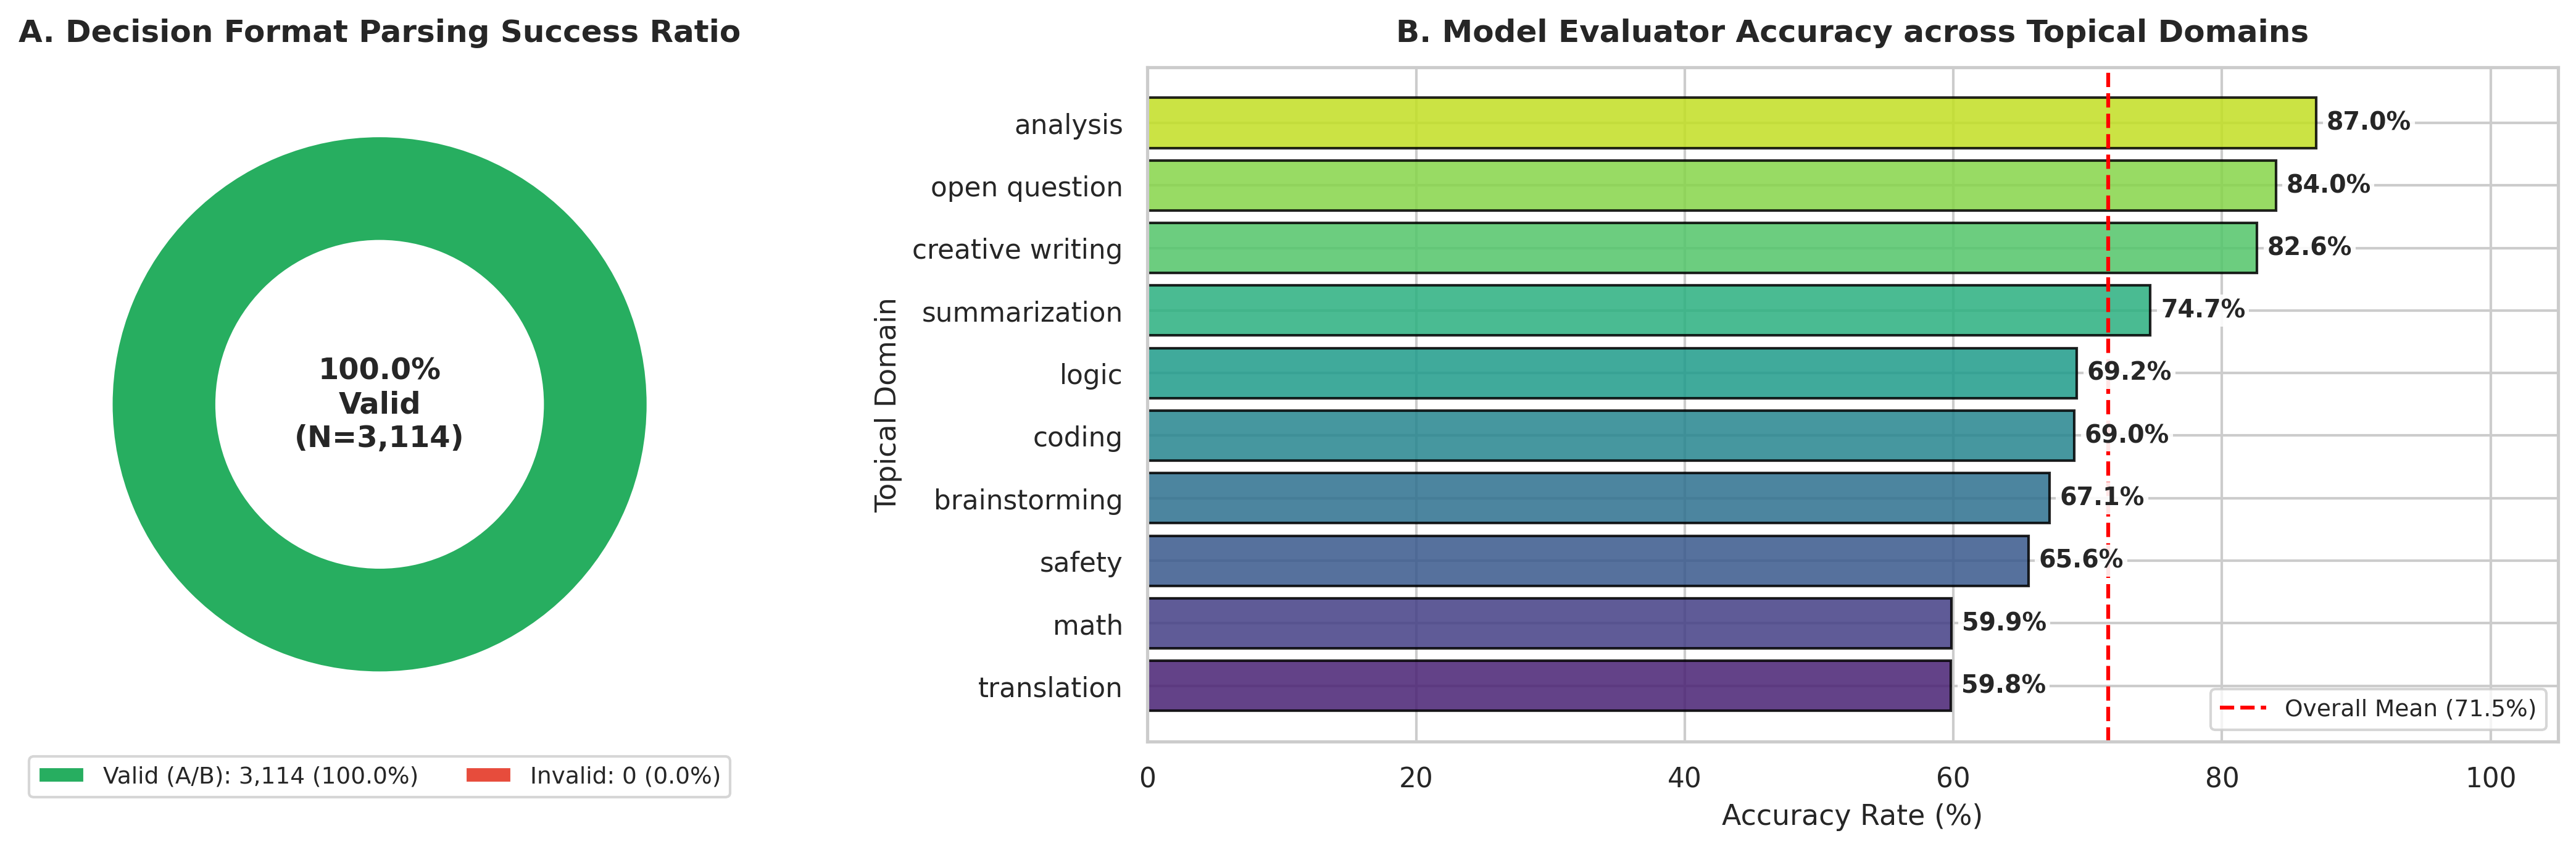

In [35]:
fig3, axes3 = plt.subplots(1, 2, figsize=(15.0, 4.8), gridspec_kw={'width_ratios': [1.0, 1.35]})

total_eval = len(df_valid) + invalid_count
valid_pct = (len(df_valid) / total_eval) * 100 if total_eval > 0 else 0.0
invalid_pct = (invalid_count / total_eval) * 100 if total_eval > 0 else 0.0

axes3[0].pie([len(df_valid), invalid_count] if invalid_count > 0 else [len(df_valid)],
             colors=['#27ae60', '#e74c3c'] if invalid_count > 0 else ['#27ae60'],
             startangle=90, wedgeprops=dict(width=0.4, edgecolor='white', lw=2))
axes3[0].text(0, 0, f"{valid_pct:.1f}%\nValid\n(N={total_eval:,})", ha='center', va='center', fontweight='bold', fontsize=11.5)
axes3[0].set_title('A. Decision Format Parsing Success Ratio', fontweight='bold', pad=10)
axes3[0].legend(handles=[
    Patch(facecolor='#27ae60', label=f"Valid (A/B): {len(df_valid):,} ({valid_pct:.1f}%)"),
    Patch(facecolor='#e74c3c', label=f"Invalid: {invalid_count:,} ({invalid_pct:.1f}%)")
], loc='lower center', bbox_to_anchor=(0.5, -0.1), ncol=2, fontsize=9)

df_valid['is_correct'] = (df_valid['logical_decision'] == df_valid['logical_human']).astype(int) * 100
domain_acc = df_valid.groupby('domain')['is_correct'].mean().reset_index().sort_values('is_correct')
mean_acc = float(df_valid['is_correct'].mean())
domain_csv: str = os.path.join(RESULTS_DIR, 'domain_accuracy_summary.csv')
domain_acc.sort_values('is_correct', ascending=False).to_csv(domain_csv, index=False)
print(f"[DATASET] table='Domain Accuracy Summary' | path='{domain_csv}' | status=EXPORTED")

bars_dom = axes3[1].barh(domain_acc['domain'], domain_acc['is_correct'],
                         color=sns.color_palette('viridis', len(domain_acc)), edgecolor='black', alpha=0.85)
axes3[1].axvline(mean_acc, color='red', ls='--', lw=1.5, zorder=1, label=f'Overall Mean ({mean_acc:.1f}%)')
axes3[1].set(xlabel='Accuracy Rate (%)', ylabel='Topical Domain', xlim=(0, 105))
axes3[1].set_title('B. Model Evaluator Accuracy across Topical Domains', fontweight='bold', pad=10)
axes3[1].legend(loc='lower right', fontsize=9)
annotate_bars(axes3[1], bars=bars_dom, fmt="{:.1f}%", horizontal=True)

export_panels(fig3, axes3, ['plot_parsing_success_ratio', 'plot_domain_accuracy'])

### **8.5 Figure 4: Positional Decision Heatmap**

Membuat *heatmap* ukuran 2x2 untuk masing-masing variasi prompt (P1, P2, dan P3) yang memetakan silang identitas jawaban asli (Resp. 1 dan Resp. 2) pada urutan normal (AB) terhadap urutan terbalik (BA) guna melihat konsistensi pilihan model terlepas dari pertukaran posisi.

[VISUALIZATION] figure='plot_positional_heatmap_p1' | formats=['PNG', 'SVG'] | dir='/content/drive/MyDrive/LLMReliability/results' | status=SAVED
[VISUALIZATION] figure='plot_positional_heatmap_p2' | formats=['PNG', 'SVG'] | dir='/content/drive/MyDrive/LLMReliability/results' | status=SAVED
[VISUALIZATION] figure='plot_positional_heatmap_p3' | formats=['PNG', 'SVG'] | dir='/content/drive/MyDrive/LLMReliability/results' | status=SAVED


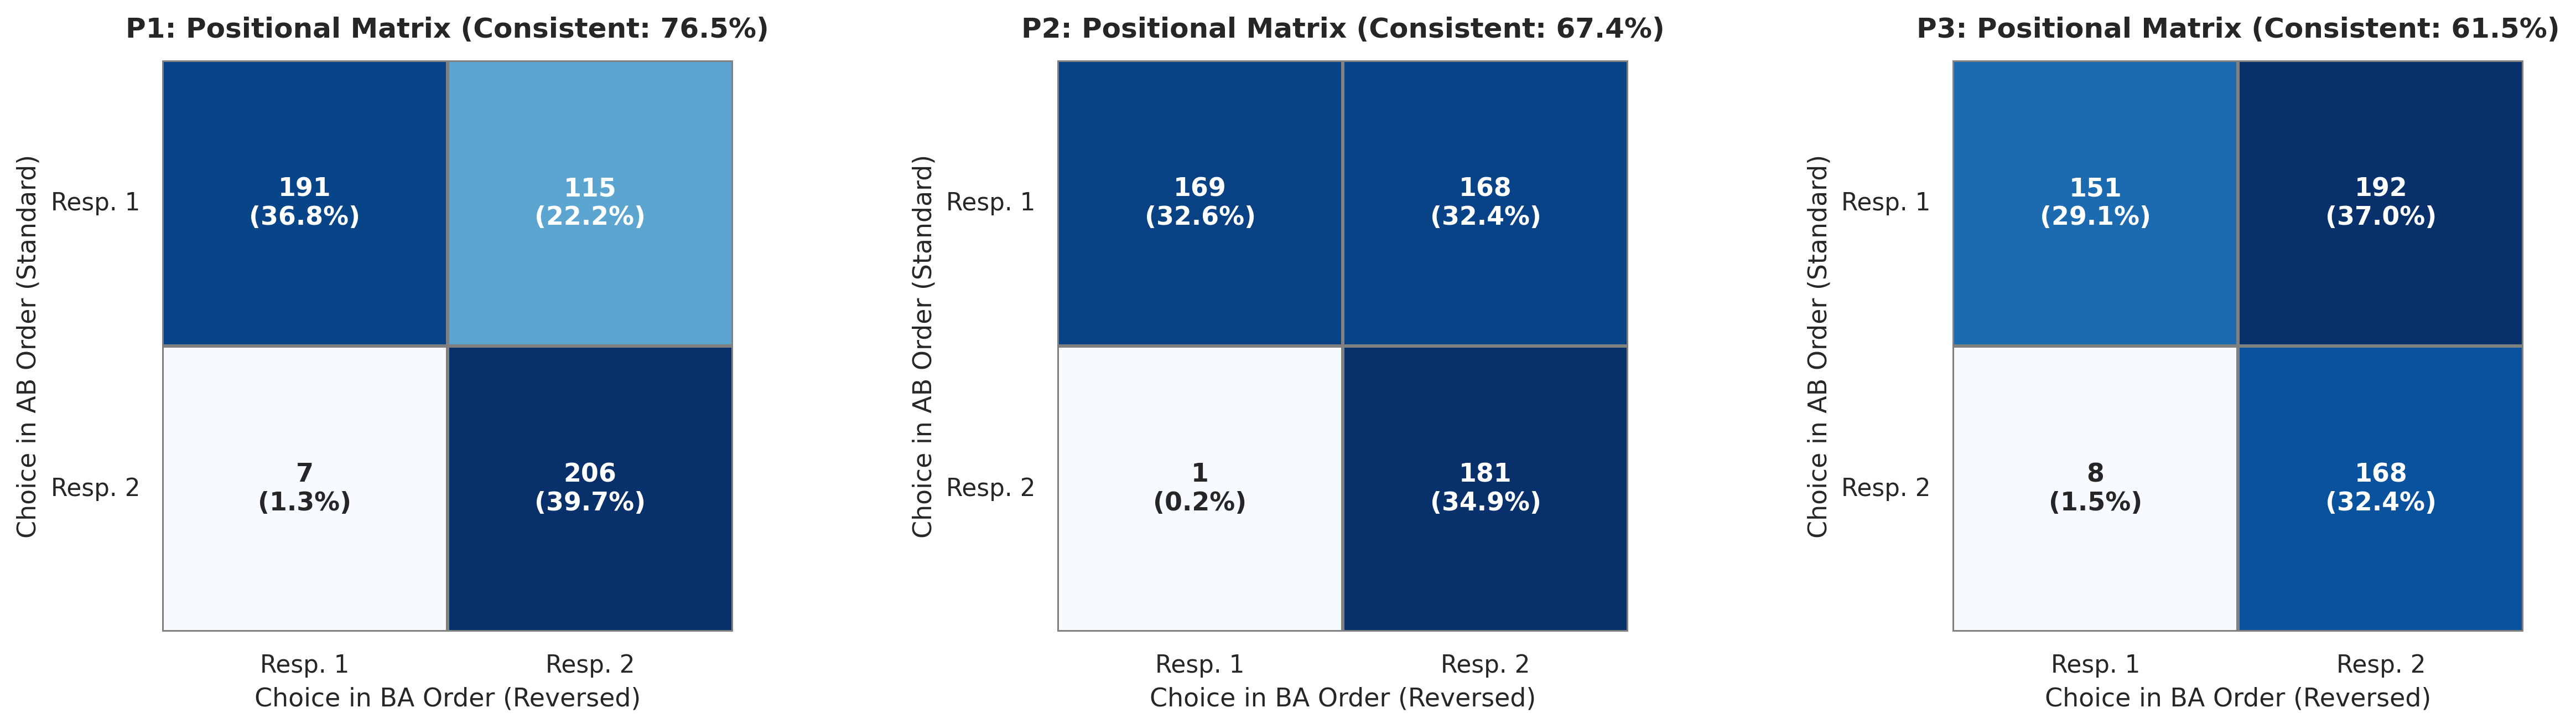

In [36]:
fig4, axes4 = plt.subplots(1, len(prompts), figsize=(16.5, 4.6))

for ax, p_id in zip(axes4, prompts):
    sub_p = df_valid[df_valid['prompt_id'] == p_id]
    paired = (sub_p[sub_p['position'] == 'AB'].set_index('sample_id')
              .join(sub_p[sub_p['position'] == 'BA'].set_index('sample_id'), lsuffix='_ab', rsuffix='_ba', how='inner'))
    ct = pd.crosstab(paired['logical_decision_ab'], paired['logical_decision_ba']).reindex(index=[1, 2], columns=[1, 2], fill_value=0)
    ct.index = ct.columns = ['Resp. 1', 'Resp. 2']
    n_pair = max(len(paired), 1)
    annot = [[f"{v}\n({v / n_pair * 100:.1f}%)" for v in row] for row in ct.to_numpy()]
    cons = (np.diag(ct).sum() / len(paired) * 100) if len(paired) > 0 else 0.0

    sns.heatmap(ct, annot=annot, fmt='', cmap='Blues', ax=ax, cbar=False, square=True,
                annot_kws={'fontsize': 11, 'fontweight': 'bold'}, linewidths=1, linecolor='gray')
    ax.set(xlabel='Choice in BA Order (Reversed)', ylabel='Choice in AB Order (Standard)')
    ax.set_title(f"{p_id}: Positional Matrix (Consistent: {cons:.1f}%)", fontweight='bold', pad=10)
    ax.tick_params(axis='y', rotation=0)

export_panels(fig4, axes4, [f"plot_positional_heatmap_{p.lower()}" for p in prompts])

### **8.6 Figure 5: Cross-Prompt Stability and Sensitivity Profile**

Memvisualisasikan perbandingan kestabilan penilaian antar pasangan prompt (P1 vs P2, P1 vs P3, dan P2 vs P3) ke dalam dua panel, yaitu persentase pilihan jawaban yang tetap konsisten pada Panel A dan persentase pilihan yang berubah (*flip rate*) pada Panel B.

[VISUALIZATION] figure='plot_prompt_consistency' | formats=['PNG', 'SVG'] | dir='/content/drive/MyDrive/LLMReliability/results' | status=SAVED
[VISUALIZATION] figure='plot_prompt_flip_rate' | formats=['PNG', 'SVG'] | dir='/content/drive/MyDrive/LLMReliability/results' | status=SAVED


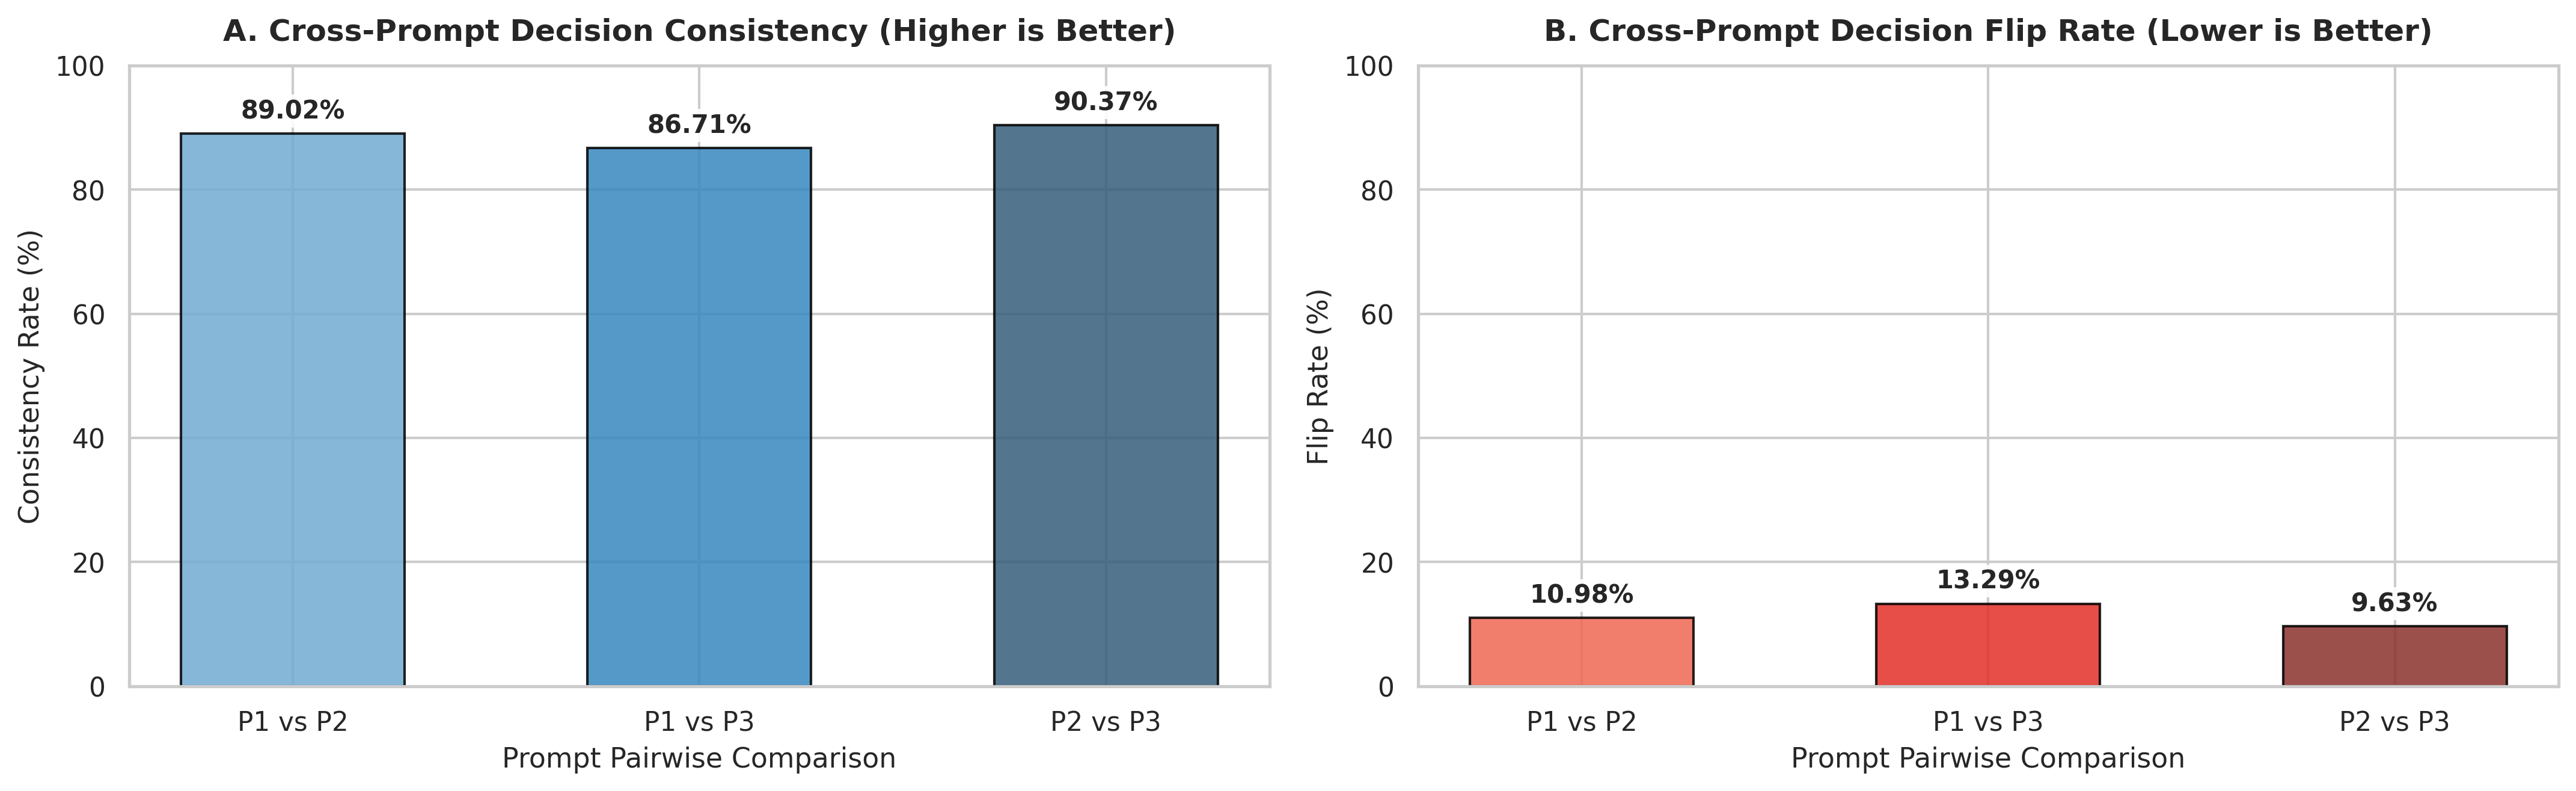

In [37]:
if 'df_prompt_stab' not in globals() or df_prompt_stab is None or df_prompt_stab.empty:
    df_prompt_stab = df_valid[df_valid['position'] == 'AB'].pivot_table(
        index='sample_id', columns='prompt_id', values='logical_decision'
    ).dropna()

if not df_prompt_stab.empty:
    pairs = [('P1 vs P2', 'P1', 'P2'), ('P1 vs P3', 'P1', 'P3'), ('P2 vs P3', 'P2', 'P3')]
    labels = [lbl for lbl, _, _ in pairs]
    cons_rates = [float((df_prompt_stab[a] == df_prompt_stab[b]).mean() * 100) for _, a, b in pairs]
    flip_rates = [100.0 - c for c in cons_rates]

    fig5, axes5 = plt.subplots(1, 2, figsize=(14.5, 4.6))
    plot_bars(axes5[0], labels, cons_rates, 'Blues_d', 'A. Cross-Prompt Decision Consistency (Higher is Better)', 'Prompt Pairwise Comparison', 'Consistency Rate (%)')
    plot_bars(axes5[1], labels, flip_rates, 'Reds_d', 'B. Cross-Prompt Decision Flip Rate (Lower is Better)', 'Prompt Pairwise Comparison', 'Flip Rate (%)')
    export_panels(fig5, axes5, ['plot_prompt_consistency', 'plot_prompt_flip_rate'])